In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.metrics import mean_absolute_error

In [95]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [96]:
# Fix random state
random_state = 42

In [97]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [98]:
apogee = apogee[apogee.parallax > 1]
print (len(apogee))
galah = galah[galah.parallax > 2]
print (len(galah))


28385
45103


# Here we focus on getting Fe from no abundance

In [99]:
columns_for_Fe = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 
       'rapo', 'rperi', 'eccentricity', 'zmax', 
       'ER', 'Ez',  'Lz',  'Or', 'Oz',  
       'Tz', 'jp', 'jr', 'jz', 
       'fe_h', ]

# excluded Tp and radial_velocity, because when training on apogee and testing on harps, the dependence of feh on these parameters for the two samples have different signs. 

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [100]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)

### Identifying and exluding null values

In [101]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [102]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [103]:
#gr8.isnull().sum() # No null values

In [104]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [105]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train], ignore_index=True)


full_df = pd.concat([apogee,   harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [106]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)


model_names = {
    'xgbr': xgbr,
    'lgbr': lgbr,
}


In [107]:
def feature_target_correlation(df, target):
    corr = df.corr(numeric_only=True)[target].drop(target).sort_values(key=abs, ascending=False)
    return corr
correlations = feature_target_correlation(df=X_full.assign(fe_h=y_full), target='fe_h')
correlations


P_gal           0.329457
zmax           -0.323857
Ez             -0.308347
abs_W_lsr      -0.294309
jz             -0.290291
VW_lsr         -0.285596
UVW_lsr        -0.281431
Tz             -0.274811
UW_lsr         -0.246890
jr             -0.246459
Oz              0.245155
Log_UVW_lsr    -0.229125
eccentricity   -0.225258
UV_lsr         -0.224000
rapo           -0.203359
rperi           0.084730
V_lsr           0.048934
jp              0.041471
Lz              0.041471
Or              0.036670
ER             -0.033255
Name: fe_h, dtype: float64

/tmp/ipykernel_266652/522446026.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")


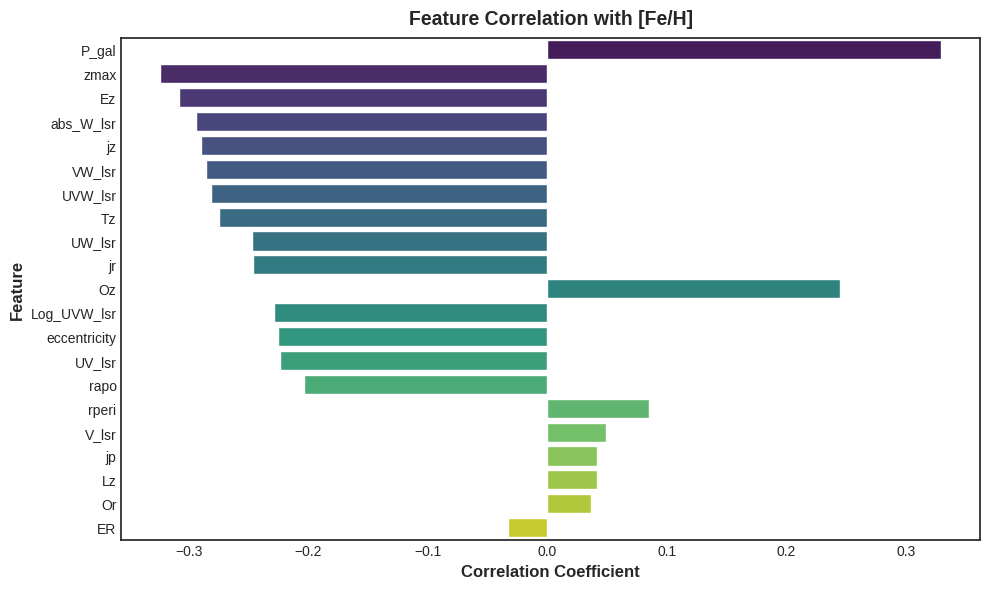

In [108]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")
plt.title('Feature Correlation with [Fe/H]')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


pandas-profiling (now renamed to ydata-profiling)
✅ What it gives:
Target correlation heatmaps

Distribution plots of features

Missing value analysis

Duplicates detection

Interaction matrices

Report export (HTML, JSON)

In [109]:
from ydata_profiling import ProfileReport
#profile = ProfileReport(X_harps.assign(fe_h=y_harps), title="EDA Report", explorative=True)
#profile.to_file("eda_report.html")  # Opens in your browser


In [110]:
import sweetviz as sv

#report = sv.analyze([harps, "Train"], target_feat="fe_h")
#report.show_html("sweetviz_report.html")


In [111]:
#sv.compare([X_combined_train.assign(fe_h=y_combined_train), "Train"], [harps, "Test"]).show_html("compare.html")


In [112]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd

def select_features_by_mi_and_correlation(X, y, corr_thresh=0.9, top_n=None, verbose=True):
    # 1. Compute mutual information
    mi = mutual_info_regression(X, y)
    mi_df = pd.DataFrame({'Feature': X.columns, 'MI': mi}).sort_values(by='MI', ascending=False)

    selected = []
    removed = []
    remaining = list(mi_df['Feature'])

    while remaining:
        # Pick the highest MI feature
        best = remaining.pop(0)
        selected.append(best)

        if verbose:
            print(f"Selected: {best} (MI={mi_df.set_index('Feature').loc[best, 'MI']:.4f})")

        # Remove features highly correlated with 'best'
        to_remove = []
        for feature in remaining:
            corr = np.corrcoef(X[best], X[feature])[0, 1]
            if abs(corr) > corr_thresh:
                to_remove.append(feature)

        for f in to_remove:
            remaining.remove(f)
            removed.append(f)
            if verbose:
                print(f"  Removed due to high correlation with {best}: {f} (|corr|={abs(np.corrcoef(X[best], X[f])[0, 1]):.2f})")

        # Stop if top_n features are selected
        if top_n and len(selected) >= top_n:
            break

    return selected, removed



In [113]:
selected_features_full, removed_features_full = select_features_by_mi_and_correlation(X_full, y_full, corr_thresh=0.95)
print("Selected:", selected_features_full)

Selected: P_gal (MI=0.0736)
Selected: zmax (MI=0.0644)
  Removed due to high correlation with zmax: Ez (|corr|=0.96)
Selected: jp (MI=0.0628)
  Removed due to high correlation with jp: Lz (|corr|=1.00)
  Removed due to high correlation with jp: Or (|corr|=0.96)
  Removed due to high correlation with jp: ER (|corr|=0.95)
  Removed due to high correlation with jp: V_lsr (|corr|=0.98)
Selected: VW_lsr (MI=0.0608)
Selected: Log_UVW_lsr (MI=0.0593)
Selected: UVW_lsr (MI=0.0581)
  Removed due to high correlation with UVW_lsr: UV_lsr (|corr|=0.96)
Selected: Oz (MI=0.0562)
  Removed due to high correlation with Oz: Tz (|corr|=0.95)
Selected: jz (MI=0.0560)
Selected: jr (MI=0.0469)
Selected: abs_W_lsr (MI=0.0463)
Selected: rperi (MI=0.0450)
Selected: eccentricity (MI=0.0446)
Selected: UW_lsr (MI=0.0379)
Selected: rapo (MI=0.0338)
Selected: ['P_gal', 'zmax', 'jp', 'VW_lsr', 'Log_UVW_lsr', 'UVW_lsr', 'Oz', 'jz', 'jr', 'abs_W_lsr', 'rperi', 'eccentricity', 'UW_lsr', 'rapo']


First 21 of 21 features:
P_gal           0.070943
zmax            0.064301
jp              0.063481
Lz              0.063481
VW_lsr          0.060469
Log_UVW_lsr     0.058981
UVW_lsr         0.057879
Oz              0.056996
jz              0.056512
Tz              0.055415
Or              0.051800
ER              0.049815
UV_lsr          0.048677
Ez              0.047884
V_lsr           0.047740
abs_W_lsr       0.047207
jr              0.046445
rperi           0.045173
eccentricity    0.042995
UW_lsr          0.038080
rapo            0.034170
Name: MI Scores, dtype: float64


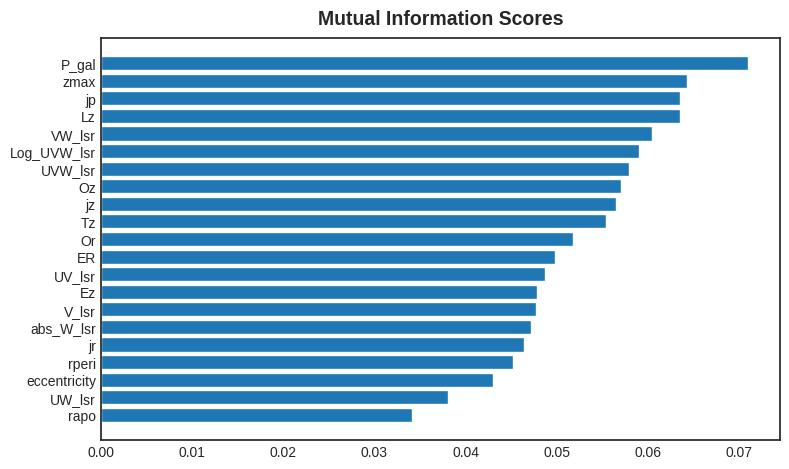

In [114]:
mi_scores_full = make_mi_scores(X_full, y=y_full,  plot = True)

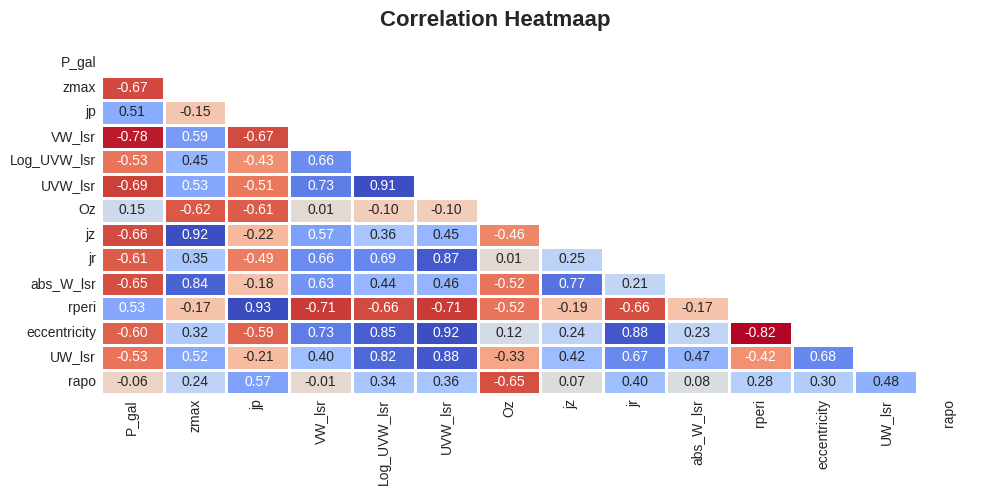

In [115]:
# Displays the correlation hitmap
corr_heatmap_plot(X_full[selected_features_full])

In [116]:
from statsmodels.tools.tools import add_constant
import numpy as np

X_new = X_full[selected_features_full].copy()
X_new = add_constant(X_new)

vif_data = []
for i in range(X_new.shape[1]):
    try:
        vif_value = variance_inflation_factor(X_new.values, i)
    except Exception as e:
        vif_value = np.inf
        print(f"Failed VIF for {X_new.columns[i]}: {e}")
    vif_data.append((X_new.columns[i], vif_value))

vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
print(vif_df[vif_df['VIF'] > 0])  # or any threshold you like



        Variable          VIF
0          const  4486.442314
1          P_gal     4.733933
2           zmax    26.731689
3             jp   429.475302
4         VW_lsr    25.873991
5    Log_UVW_lsr    16.690129
6        UVW_lsr   183.931147
7             Oz    18.777181
8             jz    12.499836
9             jr    55.387794
10     abs_W_lsr    11.573622
11         rperi   190.176407
12  eccentricity    95.922486
13        UW_lsr    51.149005
14          rapo   157.064454


In [117]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [118]:
baseline_results = model_test_CV_models(X_combined_train[selected_features_full], y_combined_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 1.42s → MAE: 0.148 ± 0.002

Scoring model: lgbr
lgbr done in 3.83s → MAE: 0.143 ± 0.002

xgbr     | MAE: 0.148 ± 0.002
lgbr     | MAE: 0.143 ± 0.002


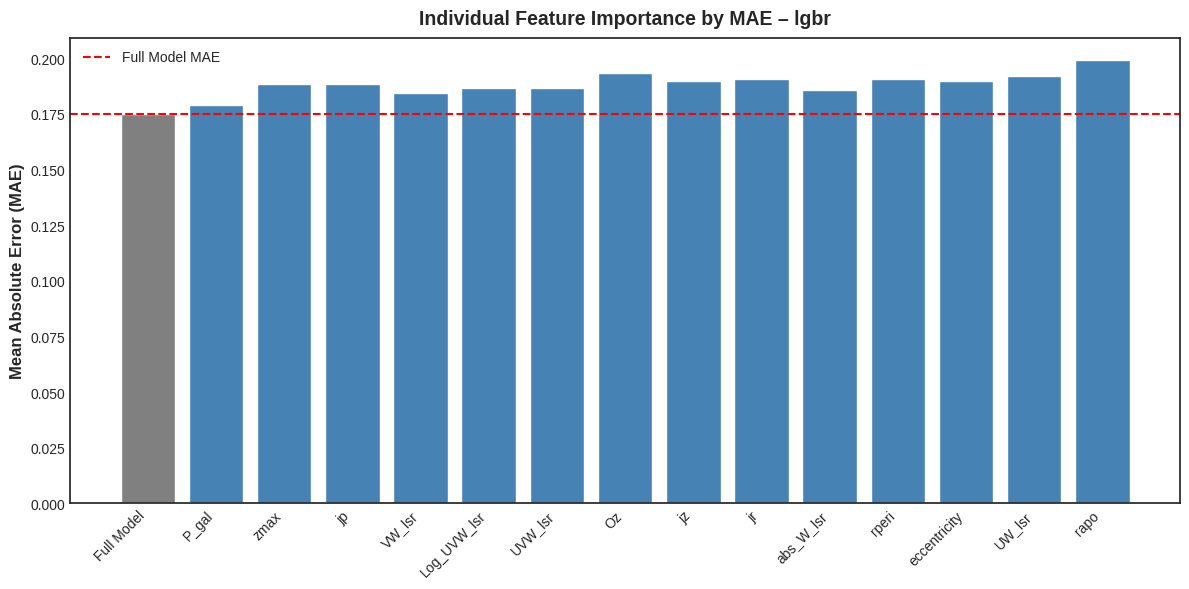

In [119]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    mae_full = mean_absolute_error(y_test, y_pred_full)

    # Individual feature performance
    mae_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        mae_individual.append(mean_absolute_error(y_test, y_pred_feat))

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [mae_full] + mae_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=mae_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Mean Absolute Error (MAE)')
    plt.title(f'Individual Feature Importance by MAE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()


# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
individual_feature_importance(model, 'lgbr', X_combined_train[selected_features_full], y_combined_train, X_harps[selected_features_full], y_harps)

Feature importance: ['P_gal' 'rapo' 'abs_W_lsr' 'Oz' 'jp' 'VW_lsr' 'jz' 'zmax' 'rperi'
 'UVW_lsr' 'Log_UVW_lsr' 'eccentricity' 'jr' 'UW_lsr']


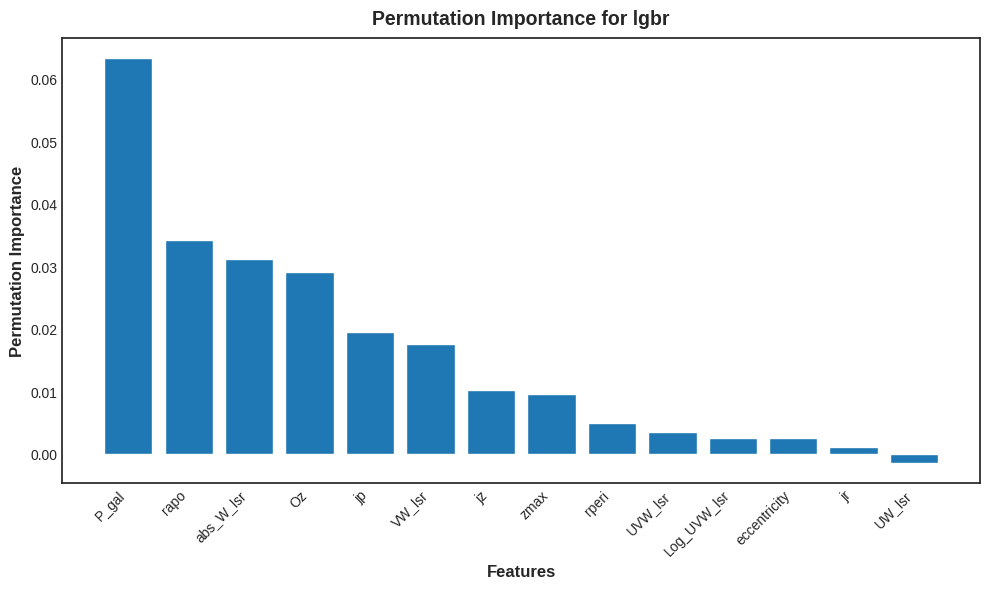

In [120]:
def feat_importance_permut(model, model_name, X, y, n_repeats = 10):
    from sklearn.inspection import permutation_importance

    X_trian, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_trian, y_train)
    

    # Calculate MAE on the original test set
    y_pred = model.predict(X_test)
    mae_original = mean_absolute_error(y_test, y_pred)

    # Use permutation importance to obtain feature importances
    result = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=42)

    # Get feature importances and indices
    feature_importances = result.importances_mean
    sorted_indices = feature_importances.argsort()[::-1]

    print (f'Feature importance: {X.columns[sorted_indices].values}')

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(sorted_indices)), feature_importances[sorted_indices], tick_label=X.columns[sorted_indices])
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title(f'Permutation Importance for {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

feat_importance_permut(model, 'lgbr', X_combined_train[selected_features_full], y_combined_train, n_repeats = 10)

In [121]:
def ols(x, y):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const)
    results = model.fit()
    coeff1_ols, coeff2_ols = results.params[0], results.params[1]
    p_values = results.pvalues
    return coeff1_ols, coeff2_ols, p_values

In [ ]:
selected_features = ['P_gal',
 'zmax',
 'jp',
 'VW_lsr',
 'Log_UVW_lsr',
 'UVW_lsr',
 'Oz',
 'jz',
 'jr',
 'abs_W_lsr',
 'rperi',
 'eccentricity',
 'UW_lsr',
 'rapo']

['P_gal',
 'zmax',
 'jp',
 'VW_lsr',
 'Log_UVW_lsr',
 'UVW_lsr',
 'Oz',
 'jz',
 'jr',
 'abs_W_lsr',
 'rperi',
 'eccentricity',
 'UW_lsr',
 'rapo']

MAE = 0.17


/tmp/ipykernel_266652/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_266652/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_266652/3185111557.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.title(f'{p_value[1]:.2f}')
/tmp/ipykernel_266652/403

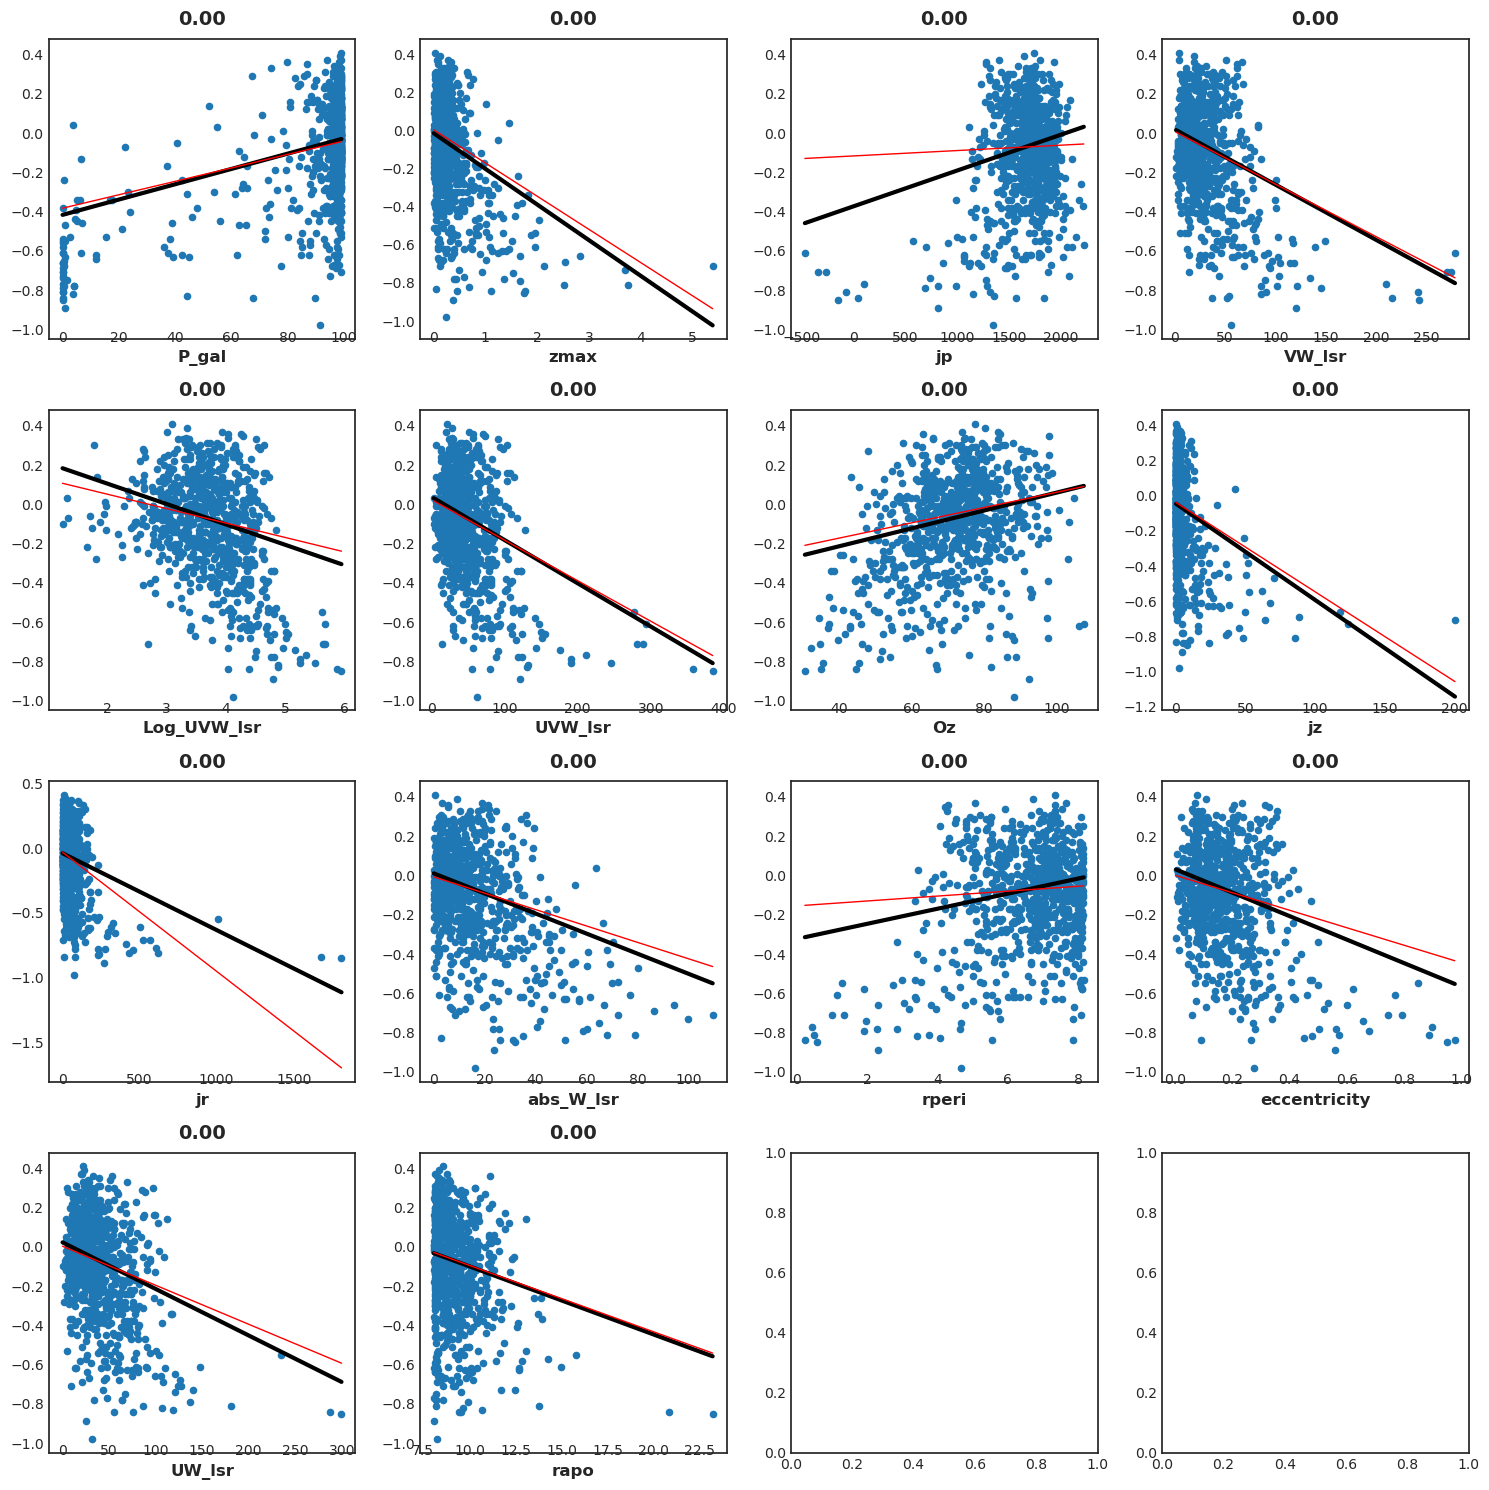

In [124]:
def dependence_on_feature_plot(model, X, y, X_test, y_test):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    print (f'MAE = {mean_absolute_error(y_test, y_pred):.2f}')

    sns.set_style('white')
    fig, ax = plt.subplots(4, 4, figsize=(15, 15))

    for i, feature in enumerate(X.columns, start=1):

        coeff1_ols, coeff2_ols, p_value = ols(X_test[feature], y_pred)
        coeff1_train_ols, coeff2_train_ols, p_value_train = ols(X[feature], y)

        x_line = np.array(np.arange(np.min(X_test[feature]), np.max(X_test[feature]),0.001))
        y_line = coeff1_ols +  coeff2_ols *x_line
        y_line_train = coeff1_train_ols +  coeff2_train_ols *x_line

        plt.subplot(4, 4, i)
        plt.scatter(X_test[feature], y_test, s = 20)
        plt.plot(x_line, y_line, color = 'black', lw = 3)
        plt.plot(x_line, y_line_train, color = 'red', lw = 1, label = 'Train')
        plt.xlabel(feature, fontsize=12)
        plt.title(f'{p_value[1]:.2f}')
        plt.tick_params(axis='x', which='major', labelsize=10, pad=-6)
        plt.tick_params(axis='y', which='major', labelsize=10)


dependence_on_feature_plot(model, X_combined_train[selected_features_full], y_combined_train, X_harps[selected_features_full], y_harps)